# Peptide retention: an improved worked example

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/05_LLM_Tools/notebooks/TD4_peptide_RT_improved.ipynb)

This notebook is a worked example for the TD4 project. It starts from the reference approach
in the instructor copy: amino-acid counts with a linear model, which reaches a test MAE of about
12.4 iRT units. It then improves the predictions in three steps. Each step starts from a plot that
shows what the previous model gets wrong, and then changes one thing to fix it.

| Step | What the model sees | Why it should help |
|---|---|---|
| 0. Baseline | Nothing: it predicts the training mean | Reference point that any useful model must beat |
| 1. Composition | How many of each amino acid the peptide contains | Hydrophobic residues increase retention |
| 2. Composition + position | Step 1, plus composition relative to length and the first three residues | Residue effects depend on peptide length and on position near the N-terminus |
| 3. Sequence model (GRU) | The full sequence, read residue by residue | Learns order, neighbour and terminal effects from the data |

Run the cells from top to bottom. The notebook runs on a free Colab CPU in about 5 minutes.
Neural-network results can differ slightly between computers, so your numbers may differ a little
from the numbers quoted in the text.

> **Instructor note.** Like the instructor copy, this is one defensible workflow, not the expected
> answer. Do not give it to students before they have made their own choices.

### How to read the Python code in this notebook

You do not need to write code for this notebook, but you can read it. Every code cell is
commented. A few rules help:

| You see | It means |
|---|---|
| `# some text` | A **comment**: an explanation for humans. Python ignores it. |
| `name = value` | Store a value under a name (a **variable**), to use it later. |
| `import numpy as np` | Load a **library** (a toolbox of ready-made code) and give it a short name. |
| `def name(inputs):` followed by indented lines | Define a **function**: a reusable recipe. It runs only when it is called, for example `name(x)`. |
| `for item in collection:` followed by indented lines | A **loop**: repeat the indented lines once for each item. |
| `if condition:` / `else:` | Run the indented lines only if the condition is true (or false). |
| `class Name(nn.Module):` | Define a new kind of object, here a neural network with its own parts and its own `forward` recipe. |
| `object.method()` | Ask an object to do something, for example `data.head()` shows the first rows of a table. |
| `[a, b, c]` and `{"key": value}` | A **list** (ordered items) and a **dictionary** (values looked up by name). |
| `[x * 2 for x in values]` | A **list comprehension**: build a list by repeating an expression for each item. |
| `f"text {value}"` | An **f-string**: text in which the values inside `{}` are filled in. |
| `assert condition, "message"` | A **check**: stop with the message if the condition is false. |

The main libraries are **pandas** (tables), **NumPy** (arrays of numbers), **Matplotlib** (plots),
**scikit-learn** (classical machine learning: the baseline and the Ridge models) and **PyTorch**
(neural networks: the GRU). Indentation (spaces at the start of a line) matters in Python: it shows
which lines belong together.

## 1. Load the data

We use the same 6,000 peptides as the student notebook: a fixed random subset of the
DLOmix / ProteomeTools data. Each row has a peptide `sequence` (the input) and an `irt` value
(the target). iRT is a calibrated retention index without time units. Larger values mean later
elution in reversed-phase LC.

In [1]:
# pandas is the library for tables (DataFrames); 'as pd' gives it a short name
import pandas as pd

# Address of the data file on GitHub (a fixed version, so the data never change)
DATA_URL = (
    "https://raw.githubusercontent.com/wilhelm-lab/dlomix/"
    "f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv"
)
# Read the file into a table, then take a fixed random subset of 6,000 peptides.
# random_state=42 fixes the random choice, so everybody gets the same peptides;
# reset_index numbers the rows again from 0.
data = pd.read_csv(DATA_URL).sample(n=6000, random_state=42).reset_index(drop=True)
# Show the first 5 rows of the table
data.head()

,sequence,irt
0,DLPVDSLEGEDFEK,91.048184
1,EMCTVEEPNEEFTSR,48.897757
2,AVSVFFR,82.850771
3,ESFIVLESKPK,59.681840
4,TGAVGDLVIIGDR,95.640349


In [2]:
# Load the libraries (toolboxes) used in this notebook
import copy  # to make independent copies of objects (used to save the best model)
import time  # to measure how long things take

import numpy as np  # arrays of numbers and fast calculations on them
import matplotlib.pyplot as plt  # plotting
import torch  # PyTorch: neural networks
from torch import nn  # nn contains the building blocks of neural networks
from sklearn.model_selection import train_test_split  # to split the data into parts
from sklearn.dummy import DummyRegressor  # a baseline model that always predicts the mean
from sklearn.linear_model import Ridge  # linear regression with a penalty on large weights
from sklearn.pipeline import make_pipeline  # to chain processing steps
from sklearn.preprocessing import StandardScaler  # to rescale each feature to mean 0 and spread 1
from sklearn.metrics import mean_absolute_error, r2_score  # error measures

# Fix the random number generators so that the results can be repeated
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# The 20 standard amino acids, one letter each
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

# Chemical class of each residue (side-chain behaviour at the acidic pH of RP-LC)
# A dictionary: amino acid -> chemical class. dict.fromkeys("AVLIM", ...) gives the same
# value to A, V, L, I and M; the ** operator merges the small dictionaries into one.
AA_CLASS = {
    **dict.fromkeys("AVLIM", "aliphatic / hydrophobic"),
    **dict.fromkeys("FWY", "aromatic"),
    **dict.fromkeys("STNQC", "polar"),
    **dict.fromkeys("GP", "glycine / proline"),
    **dict.fromkeys("DE", "acidic"),
    **dict.fromkeys("KRH", "basic (positive at low pH)"),
}
# One colour (as a hexadecimal code) per chemical class, used in all amino-acid plots
CLASS_COLORS = {
    "aliphatic / hydrophobic": "#D9822B",
    "aromatic": "#8E5BB5",
    "polar": "#4DA3A3",
    "glycine / proline": "#9E9E9E",
    "acidic": "#C94C4C",
    "basic (positive at low pH)": "#3F6FB5",
}
# One colour per approach, used in every comparison figure
MODEL_COLORS = {
    "Training mean": "#B0B0B0",
    "Composition (Ridge)": "#8FB3DE",
    "Composition + position (Ridge)": "#2E5E9E",
    "Sequence model (GRU)": "#E07B39",
}

# General look of all plots: resolution, font size, light grid, no top and right frame lines
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("PyTorch", torch.__version__, "| ready")

PyTorch 2.15.0+cu132 | ready


## 2. Check the data and split it once

We check for missing values, repeated sequences and unexpected letters. Then we make one split
that every approach uses: 60% training, 20% validation and 20% test. It is the same split
(seed 42) as in the instructor copy, so the numbers can be compared directly.

- **Training peptides**: the models learn from these.
- **Validation peptides**: we use these to compare approaches and make decisions.
- **Test peptides**: we use these once, at the end, to report the final error.

From here on, all exploration and diagnosis uses training peptides only.

In [3]:
# Checks: each 'assert' stops the notebook with a message if its condition is false.
# .isna() marks missing values; .is_unique is True if no sequence occurs twice;
# .str.fullmatch(...) checks that each sequence uses only the 20 standard letters.
assert not data.isna().any().any(), "Missing values found"
assert data["sequence"].is_unique, "Repeated sequences found"
assert data["sequence"].str.fullmatch(f"[{AMINO_ACIDS}]+").all(), "Unexpected letters found"
print(f"{len(data)} peptides: no missing values, no repeated sequences, only the 20 standard amino acids.")
print("Length:", data["sequence"].str.len().min(), "to", data["sequence"].str.len().max(), "residues")
# .str[-1] takes the last letter; .value_counts() counts how often each letter occurs
print("Last residue:", data["sequence"].str[-1].value_counts().to_dict(), "(tryptic peptides end in K or R)")

# Split once: 20% test, then 25% of the rest (= 20% of all) for validation, 60% training
development, test = train_test_split(data, test_size=0.20, random_state=SEED)
train, validation = train_test_split(development, test_size=0.25, random_state=SEED)
# No peptide may appear in two parts (isdisjoint = no common element)
assert set(train["sequence"]).isdisjoint(validation["sequence"])
assert set(development["sequence"]).isdisjoint(test["sequence"])

# The targets (recorded iRT) of each part, as NumPy arrays
y_train = train["irt"].to_numpy()
y_validation = validation["irt"].to_numpy()
y_test = test["irt"].to_numpy()
print(f"Training: {len(train)}   Validation: {len(validation)}   Test: {len(test)}")

6000 peptides: no missing values, no repeated sequences, only the 20 standard amino acids.
Length: 7 to 40 residues
Last residue: {'R': 3188, 'K': 2812} (tryptic peptides end in K or R)
Training: 3600   Validation: 1200   Test: 1200


## 3. Look at the training data

Before building a model, we check how the target relates to two simple peptide properties:
length and average hydrophobicity. For hydrophobicity we use the Kyte-Doolittle scale, a common
textbook scale, averaged over the residues (often called GRAVY).

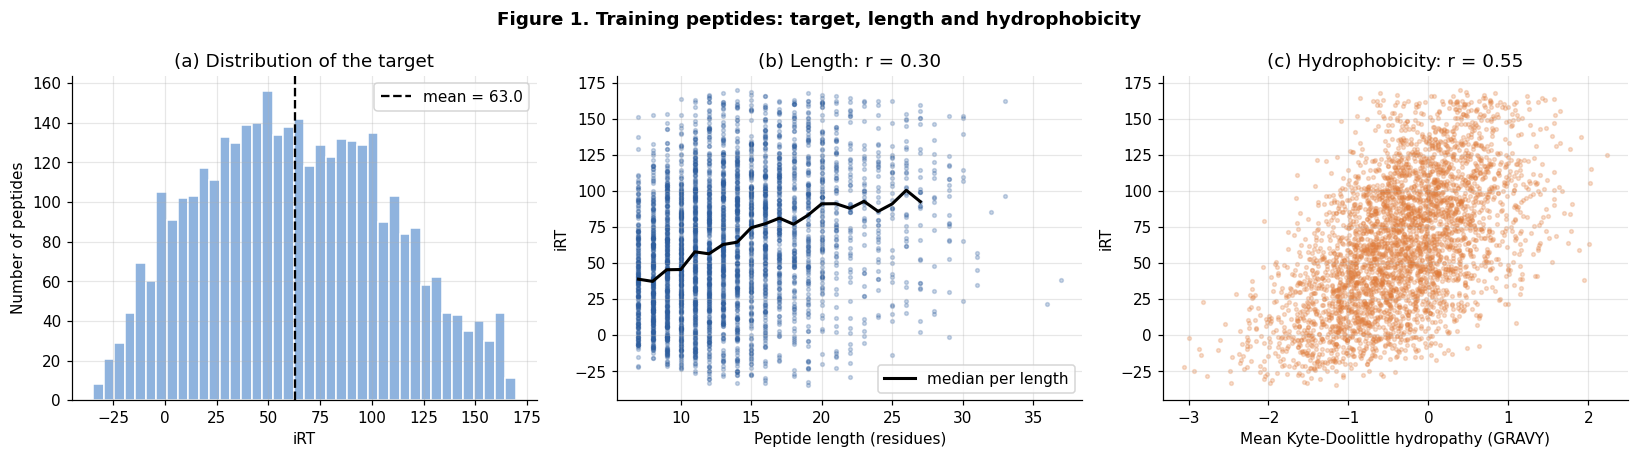

In [4]:
# Kyte-Doolittle hydropathy scale (positive = hydrophobic)
KYTE_DOOLITTLE = {"A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
                  "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
                  "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2}

# Length of each training peptide (.str.len() counts the letters)
length = train["sequence"].str.len()
# Mean hydropathy of each peptide. .map(...) applies a small function to every sequence;
# 'lambda s: ...' is a one-line function: look up the value of each residue and average them.
gravy = train["sequence"].map(lambda s: np.mean([KYTE_DOOLITTLE[aa] for aa in s]))

# Create a figure with 3 plot areas side by side: axes[0], axes[1], axes[2]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# (a) Histogram: how many peptides fall in each iRT interval (40 intervals)
axes[0].hist(y_train, bins=40, color="#8FB3DE", edgecolor="white")
axes[0].axvline(y_train.mean(), color="black", ls="--", label=f"mean = {y_train.mean():.1f}")
axes[0].set(xlabel="iRT", ylabel="Number of peptides", title="(a) Distribution of the target")
axes[0].legend()

# (b) One dot per peptide; alpha=0.25 makes the dots partly transparent
axes[1].scatter(length, y_train, s=6, alpha=0.25, color="#2E5E9E")
# Median iRT per length, only for lengths with at least 20 peptides (fewer would be noisy)
counts_per_length = length.value_counts()
common_lengths = counts_per_length[counts_per_length >= 20].index
median_by_length = train.groupby(length)["irt"].median().loc[sorted(common_lengths)]
axes[1].plot(median_by_length.index, median_by_length.values, color="black", lw=2,
             label="median per length")
axes[1].legend()
# np.corrcoef(...)[0, 1] is the Pearson correlation coefficient r
axes[1].set(xlabel="Peptide length (residues)", ylabel="iRT",
            title=f"(b) Length: r = {np.corrcoef(length, y_train)[0, 1]:.2f}")

# (c) The same for hydrophobicity
axes[2].scatter(gravy, y_train, s=6, alpha=0.25, color="#E07B39")
axes[2].set(xlabel="Mean Kyte-Doolittle hydropathy (GRAVY)", ylabel="iRT",
            title=f"(c) Hydrophobicity: r = {np.corrcoef(gravy, y_train)[0, 1]:.2f}")
fig.suptitle("Figure 1. Training peptides: target, length and hydrophobicity", fontweight="bold")
fig.tight_layout()
# Display the figure
plt.show()

**What to notice in Figure 1**

- (a) iRT covers a wide range, from about -40 to 170. A model that always predicts the mean
  will make large errors.
- (b) Longer peptides tend to elute later (black line), but the correlation is weak. Peptides of
  the same length elute across almost the whole range.
- (c) Hydrophobicity is clearly related to iRT, but the scatter is large. One number per peptide
  is not enough. We need a model that combines the contributions of individual residues.

## 4. Step 0 and step 1: baseline and composition model

The **baseline** ignores the sequence and predicts the training mean for every peptide.
It tells us how large the error is when we know nothing about the peptide.

The **composition model** counts each amino acid and adds the peptide length. A Ridge regression
then learns one weight per feature. Ridge is a linear model: the prediction is a weighted sum of
the counts. This is the reference approach of the instructor copy.

We use the **mean absolute error (MAE)** in iRT units: the average distance between prediction
and recorded value. Lower is better.

In [5]:
results = {}                 # training and validation MAE of each approach
validation_predictions = {}  # kept for later figures


# A function (def) is a reusable recipe: it runs only when it is called, e.g. record(...).
# This one computes the MAE of an approach on training and validation peptides and stores it.
def record(name, train_prediction, validation_prediction):
    """Store and print the training and validation MAE of one approach."""
    validation_predictions[name] = validation_prediction
    # results[name] = ... adds an entry to the dictionary under the key `name`
    results[name] = {
        "Training MAE": mean_absolute_error(y_train, train_prediction),
        "Validation MAE": mean_absolute_error(y_validation, validation_prediction),
    }
    # :32s pads the name to 32 characters and :6.2f shows 2 decimals, so the columns line up
    print(f"{name:32s} training MAE {results[name]['Training MAE']:6.2f}   "
          f"validation MAE {results[name]['Validation MAE']:6.2f}   (iRT units)")


def count_features(sequences):
    """Peptide length and the number of each amino acid."""
    # Start a dictionary with one column: the length of each peptide
    columns = {"length": sequences.str.len()}
    for aa in AMINO_ACIDS:  # repeat the next line for each of the 20 amino acids
        columns[aa] = sequences.str.count(aa)  # how often this letter occurs in each peptide
    return pd.DataFrame(columns, index=sequences.index)  # turn the dictionary into a table


# Hand check: ACCA has length 4, two A and two C, and nothing else
check = count_features(pd.Series(["ACCA"]))
assert check.loc[0, "length"] == 4 and check.loc[0, "A"] == 2 and check.loc[0, "C"] == 2
assert check.loc[0, list("DEFGHIKLMNPQRSTVWY")].sum() == 0
print("Hand check passed for count_features.\n")

# Compute the features of each part of the data (X is the usual name for model inputs)
X_train_counts = count_features(train["sequence"])
X_validation_counts = count_features(validation["sequence"])
X_test_counts = count_features(test["sequence"])

# Step 0: .fit(X, y) learns from the training peptides; the dummy model only learns the mean.
# .predict(X) returns one prediction per peptide.
baseline = DummyRegressor(strategy="mean").fit(X_train_counts, y_train)
record("Training mean", baseline.predict(X_train_counts), baseline.predict(X_validation_counts))

# Step 1: rescale each feature, then fit a Ridge regression. alpha=10 sets the strength of the
# penalty on large weights, which keeps the model stable.
composition_model = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train_counts, y_train)
record("Composition (Ridge)",
       composition_model.predict(X_train_counts), composition_model.predict(X_validation_counts))

Hand check passed for count_features.

Training mean                    training MAE  37.82   validation MAE  37.36   (iRT units)
Composition (Ridge)              training MAE  12.39   validation MAE  12.66   (iRT units)


The composition model reduces the error by about a factor of three compared with the baseline.

### What did the composition model learn?

A linear model on counts gives each amino acid one **retention contribution**, in iRT units per
residue. The prediction for a peptide is the sum of the contributions of its residues. This is the
same idea as the classical retention-coefficient models used in RP-LC, such as SSRCalc.
Because the weights are in iRT units, we can read them directly and compare them with chemistry.

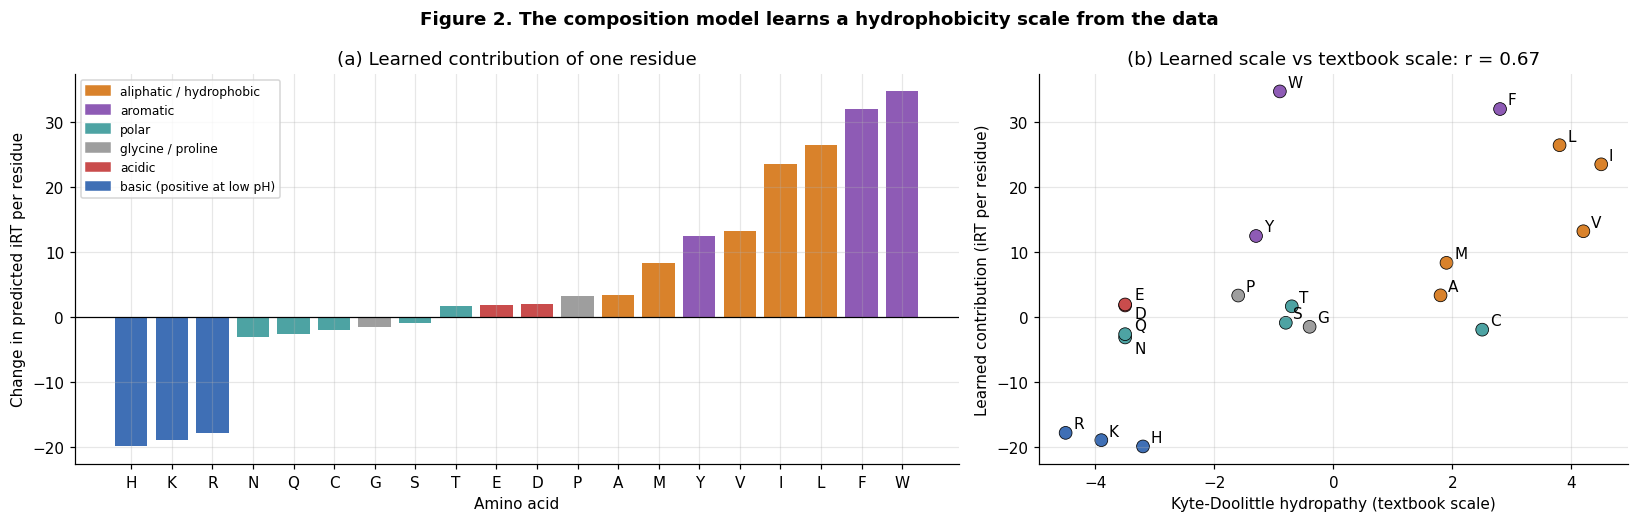

In [6]:
# Take the two steps out of the fitted pipeline: the scaler and the Ridge regression
scaler = composition_model.named_steps["standardscaler"]
ridge = composition_model.named_steps["ridge"]
# ridge.coef_ holds the learned weights (one per feature). They apply to rescaled features,
# so we divide by the scale to get iRT units per residue.
weights = pd.Series(ridge.coef_ / scaler.scale_, index=X_train_counts.columns)  # per residue, not per SD
# Adding one residue raises its count by 1 and the length by 1, so its effect is the sum of both weights
residue_effect = (weights[list(AMINO_ACIDS)] + weights["length"]).sort_values()
colors = [CLASS_COLORS[AA_CLASS[aa]] for aa in residue_effect.index]  # a list comprehension: one colour per amino acid, in the sorted order

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
# (a) Bar chart of the learned contribution of each residue
axes[0].bar(residue_effect.index, residue_effect.values, color=colors)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Amino acid", ylabel="Change in predicted iRT per residue",
            title="(a) Learned contribution of one residue")
# Coloured rectangles used to build the legend of the chemical classes
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS.values()]
axes[0].legend(legend_handles, CLASS_COLORS.keys(), fontsize=8, loc="upper left")

# (b) Kyte-Doolittle values in the same order as the bars, then a scatter plot with labels
kd = pd.Series(KYTE_DOOLITTLE)[residue_effect.index]
axes[1].scatter(kd, residue_effect, c=colors, s=70, edgecolor="black", lw=0.5)
label_offset = {"D": (6, -9), "E": (6, 4), "N": (6, -10), "Q": (6, 3)}  # avoid overlapping labels
for aa in residue_effect.index:  # write the letter next to each point
    axes[1].annotate(aa, (kd[aa], residue_effect[aa]), xytext=label_offset.get(aa, (5, 3)),
                     textcoords="offset points")
axes[1].set(xlabel="Kyte-Doolittle hydropathy (textbook scale)",
            ylabel="Learned contribution (iRT per residue)",
            title=f"(b) Learned scale vs textbook scale: r = {np.corrcoef(kd, residue_effect)[0, 1]:.2f}")
fig.suptitle("Figure 2. The composition model learns a hydrophobicity scale from the data",
             fontweight="bold")
fig.tight_layout()
plt.show()

**What to notice in Figure 2**

- (a) W, F, L and I add the most retention. These residues have large non-polar side chains that
  interact strongly with the C18 stationary phase.
- (a) K, R and H have the most negative contributions. RP-LC of peptides typically uses an acidic
  mobile phase (for example 0.1% formic acid). At this pH, these side chains carry a positive
  charge. A charged peptide prefers the polar mobile phase and elutes earlier.
- (a) D and E are close to zero. Their carboxylic acid groups are mostly protonated, and therefore
  uncharged, at low pH.
- (b) The learned scale agrees only partly with the Kyte-Doolittle scale. The largest differences
  are for the aromatic residues W and Y. Kyte-Doolittle describes hydropathy in proteins, not
  retention on a C18 column. The model learned a scale that is specific to this chromatography.
- (b) Cysteine is also lower than the textbook scale suggests. In proteomics sample preparation,
  cysteines are usually alkylated (carbamidomethylated), which makes the side chain more polar
  than a free cysteine.

The model has no chemical knowledge. It found these trends from the training data alone.

## 5. Diagnose: what does the composition model miss?

To improve a model, first look at where it fails. We compute the **residual** of each training
peptide: recorded iRT minus predicted iRT. A positive residual means the peptide elutes later than
predicted. A negative residual means it elutes earlier. If the residuals show a pattern, the model
is missing some information.

We use training peptides here. The validation peptides stay untouched for the comparison of
approaches.

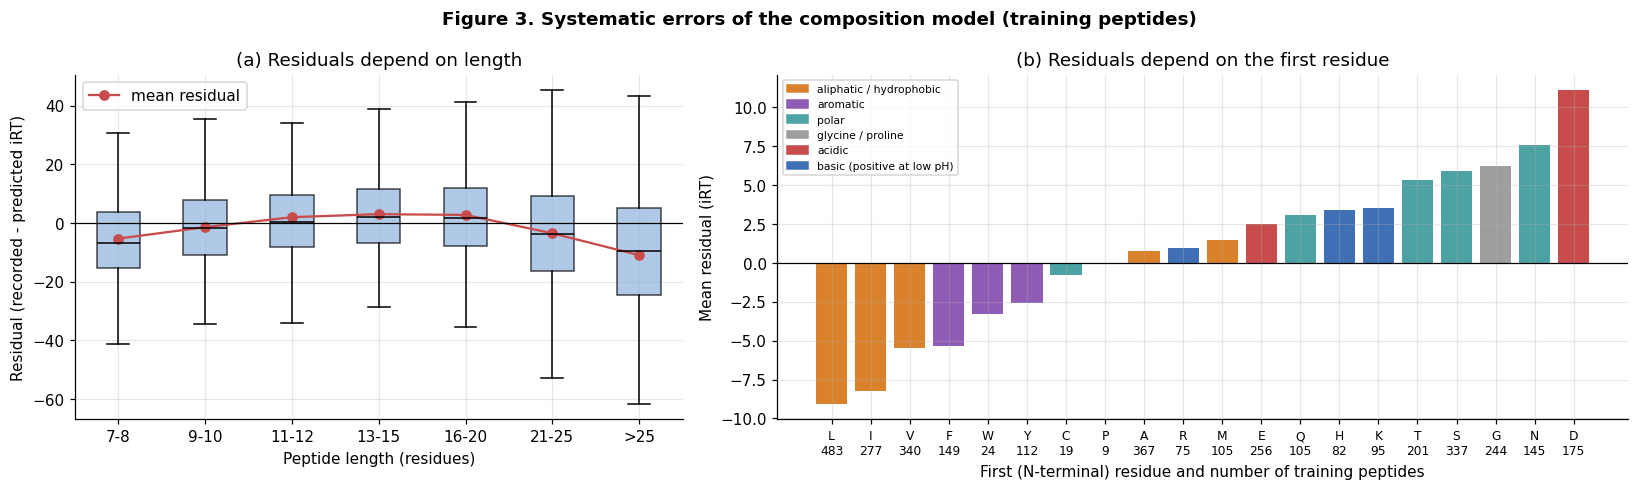

In [7]:
# A copy of the training table with two columns; .copy() leaves the original table unchanged
diagnosis = train[["sequence", "irt"]].copy()
# Residual = recorded - predicted iRT, for every training peptide
diagnosis["residual"] = diagnosis["irt"] - composition_model.predict(X_train_counts)
diagnosis["length"] = diagnosis["sequence"].str.len()
diagnosis["first residue"] = diagnosis["sequence"].str[0]  # .str[0] takes the first letter

# pd.cut puts each peptide into a length group: (0, 8], (8, 10], (10, 12], ...
length_labels = ["7-8", "9-10", "11-12", "13-15", "16-20", "21-25", ">25"]
diagnosis["length group"] = pd.cut(diagnosis["length"], [0, 8, 10, 12, 15, 20, 25, 100],
                                   labels=length_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
# One array of residuals per length group, for the box plot. groupby splits the table into
# groups; '_' stands for the group label, which we do not need here.
groups = [g["residual"].to_numpy() for _, g in diagnosis.groupby("length group", observed=False)]
# Box plot: the box spans the middle 50% of the residuals, the line inside is the median
axes[0].boxplot(groups, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#8FB3DE", "alpha": 0.7}, medianprops={"color": "black"})
axes[0].plot(range(1, len(groups) + 1), [g.mean() for g in groups], "o-", color="#C94C4C",
             label="mean residual")
axes[0].set_xticks(range(1, len(groups) + 1), length_labels)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Peptide length (residues)", ylabel="Residual (recorded - predicted iRT)",
            title="(a) Residuals depend on length")
axes[0].legend()

# Mean residual and number of peptides for each first residue, sorted by the mean
by_first = diagnosis.groupby("first residue")["residual"].agg(["mean", "count"]).sort_values("mean")
axes[1].bar(by_first.index, by_first["mean"], color=[CLASS_COLORS[AA_CLASS[aa]] for aa in by_first.index])
# Tick labels: the residue and, below it, the number of peptides that start with it
axes[1].set_xticks(range(len(by_first)), [f"{aa}\n{int(n)}" for aa, n in by_first["count"].items()],
                   fontsize=8)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="First (N-terminal) residue and number of training peptides", ylabel="Mean residual (iRT)",
            title="(b) Residuals depend on the first residue")
axes[1].legend(legend_handles, CLASS_COLORS.keys(), fontsize=7, loc="upper left")
fig.suptitle("Figure 3. Systematic errors of the composition model (training peptides)", fontweight="bold")
fig.tight_layout()
plt.show()

In [8]:
# Peptides with exactly the same composition but a different order of residues
# sorted(s) puts the letters of a peptide in alphabetical order and "".join(...) glues them back
# together: TENELLR and LLENTER both become EELLNRT. Same key = same composition.
composition_key = train["sequence"].map(lambda s: "".join(sorted(s)))
# Add the key as a column, keep only keys that occur more than once, and sort
same_composition = (train.assign(key=composition_key)
                    .groupby("key").filter(lambda g: len(g) > 1)
                    .sort_values(["key", "irt"]))
same_composition["composition-model prediction"] = composition_model.predict(
    count_features(same_composition["sequence"]))
# Show three columns, rounded to 1 decimal
same_composition[["sequence", "irt", "composition-model prediction"]].round(1)

,sequence,irt,composition-model prediction
238,VAELLLAK,72.0,81.6
3449,ALVLELAK,87.2,81.6
3748,IHTGEKPYACGQCGK,-20.3,-23.3
1458,IHTGEKPYGCAQCGK,-20.1,-23.3
3171,VQAEYNSIK,12.1,28.3
4121,AVYSIQNEK,17.4,28.3
5058,LLENTER,2.5,36.7
2030,TENELLR,26.6,36.7


**What the diagnosis shows**

1. **Length (Figure 3a).** The residuals are not centred on zero for all lengths. The shortest
   and the longest peptides elute earlier than predicted, the middle lengths slightly later.
   A model that adds a fixed amount per residue cannot describe this curve. In a long peptide,
   one extra residue has less effect than in a short peptide.
2. **N-terminal residue (Figure 3b).** Peptides that start with a hydrophobic residue (I, L, F, W,
   V) elute earlier than predicted. Peptides that start with D or N elute later. At low pH the
   N-terminal amine is positively charged. A residue next to this charge does not interact with the
   stationary phase in the same way as a residue in the middle of the peptide. Classical retention
   models such as SSRCalc include position-dependent corrections for this reason.
3. **Order (table).** Each pair in the table has the same amino-acid composition, so the
   composition model gives both peptides exactly the same prediction. Their recorded iRT values can
   differ by more than 20 units. For example, LLENTER (two leucines at the N-terminus) elutes much
   earlier than TENELLR. This is consistent with point 2.

Each finding suggests a change to the features. That is step 2.

## 6. Step 2: add composition relative to length and the N-terminal residues

We keep the linear Ridge model and add three groups of features. Each group answers one finding
of the diagnosis.

| New features | Number | Finding it addresses |
|---|---|---|
| Fraction of each amino acid (count / length) | 20 | The effect of a residue depends on peptide length |
| Logarithm of the length | 1 | Retention does not grow linearly with length |
| Identity of residues 1, 2 and 3 (one 0/1 column per amino acid and position) | 60 | Residues next to the N-terminus behave differently |

The model is still linear, so it remains fast and easy to inspect.

In [9]:
N_TERMINAL_POSITIONS = 3  # number of N-terminal positions described separately


def position_features(sequences):
    """Counts and length, plus composition relative to length, log length and the first residues."""
    length = sequences.str.len()
    counts = count_features(sequences)
    # New features are collected in a dictionary: feature name -> column of values
    extra = {"log_length": np.log(length)}
    for aa in AMINO_ACIDS:
        extra[f"{aa}_fraction"] = counts[aa] / length  # e.g. A_fraction = number of A / length
    for position in range(N_TERMINAL_POSITIONS):  # position = 0, 1, 2
        for aa in AMINO_ACIDS:
            extra[f"N{position + 1}_{aa}"] = (sequences.str[position] == aa).astype(int)  # 1 if the residue at this position is aa, else 0
    return pd.concat([counts, pd.DataFrame(extra, index=sequences.index)], axis=1)  # glue the old and new columns side by side (axis=1)


# Hand check on ACCA: A is half of the residues; positions 1, 2, 3 hold A, C, C
check = position_features(pd.Series(["ACCA"]))
# .shape[1] is the number of columns: 20 counts + length, log length, 20 fractions, 60 positions
assert check.shape[1] == 21 + 1 + 20 + 3 * 20
assert check.loc[0, "A_fraction"] == 0.5 and check.loc[0, "C_fraction"] == 0.5
assert check.loc[0, "N1_A"] == 1 and check.loc[0, "N2_C"] == 1 and check.loc[0, "N3_C"] == 1
assert check.loc[0, [c for c in check.columns if c.startswith("N")]].sum() == 3
print(f"Hand check passed for position_features ({check.shape[1]} features).\n")

X_train_position = position_features(train["sequence"])
X_validation_position = position_features(validation["sequence"])
X_test_position = position_features(test["sequence"])

# The same Ridge model as in step 1, now with 102 features
position_model = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train_position, y_train)
record("Composition + position (Ridge)",
       position_model.predict(X_train_position), position_model.predict(X_validation_position))

Hand check passed for position_features (102 features).



Composition + position (Ridge)   training MAE   8.92   validation MAE   9.27   (iRT units)


### Which new features helped?

We add the feature groups one at a time and measure the validation MAE each time. This shows
whether each change actually helps, instead of trusting the explanation in advance.

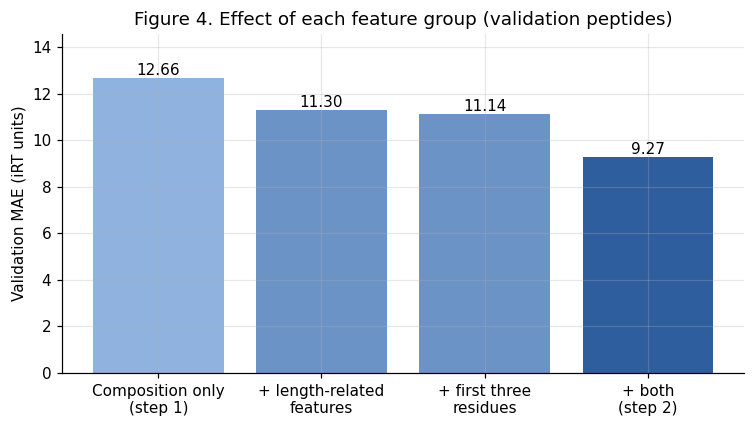

In [10]:
# Names of the columns in each feature group (lists of text)
count_columns = list(X_train_counts.columns)
length_columns = ["log_length"] + [f"{aa}_fraction" for aa in AMINO_ACIDS]
terminal_columns = [c for c in X_train_position.columns if c.startswith("N") and "_" in c]  # the N1_, N2_ and N3_ columns
# Four feature sets to compare; + joins two lists
feature_sets = {
    "Composition only\n(step 1)": count_columns,
    "+ length-related\nfeatures": count_columns + length_columns,
    "+ first three\nresidues": count_columns + terminal_columns,
    "+ both\n(step 2)": count_columns + length_columns + terminal_columns,
}
ablation = {}
# Fit one Ridge model per feature set and store its validation MAE
for label, columns in feature_sets.items():
    model = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train_position[columns], y_train)
    ablation[label] = mean_absolute_error(y_validation, model.predict(X_validation_position[columns]))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(ablation.keys(), ablation.values(),
              color=["#8FB3DE", "#6C93C6", "#6C93C6", "#2E5E9E"])
ax.bar_label(bars, fmt="%.2f")  # write the value on top of each bar
ax.set(ylabel="Validation MAE (iRT units)", ylim=(0, max(ablation.values()) * 1.15),
       title="Figure 4. Effect of each feature group (validation peptides)")
plt.show()

**What to notice in Figure 4.** Each group helps on its own, by a similar amount. Together they
help more than the sum of the two separate gains. The two groups correct different errors (length
and N-terminus), so their benefits add up rather than overlap.

The linear model is now close to its limit: it can only add fixed contributions. To learn effects
of order and of neighbouring residues, we need a model that reads the sequence.

## 7. Step 3: a sequence model that reads the peptide in order

### Turning a sequence into numbers without losing the order

We encode each peptide as a table with one row per position and one column per amino acid.
Each row contains a single 1 in the column of the residue at that position, and 0 elsewhere.
This is called **one-hot encoding**. Unlike counts, it keeps the full order of the residues.
Figure 5 shows this for the pair TENELLR and LLENTER from section 5.

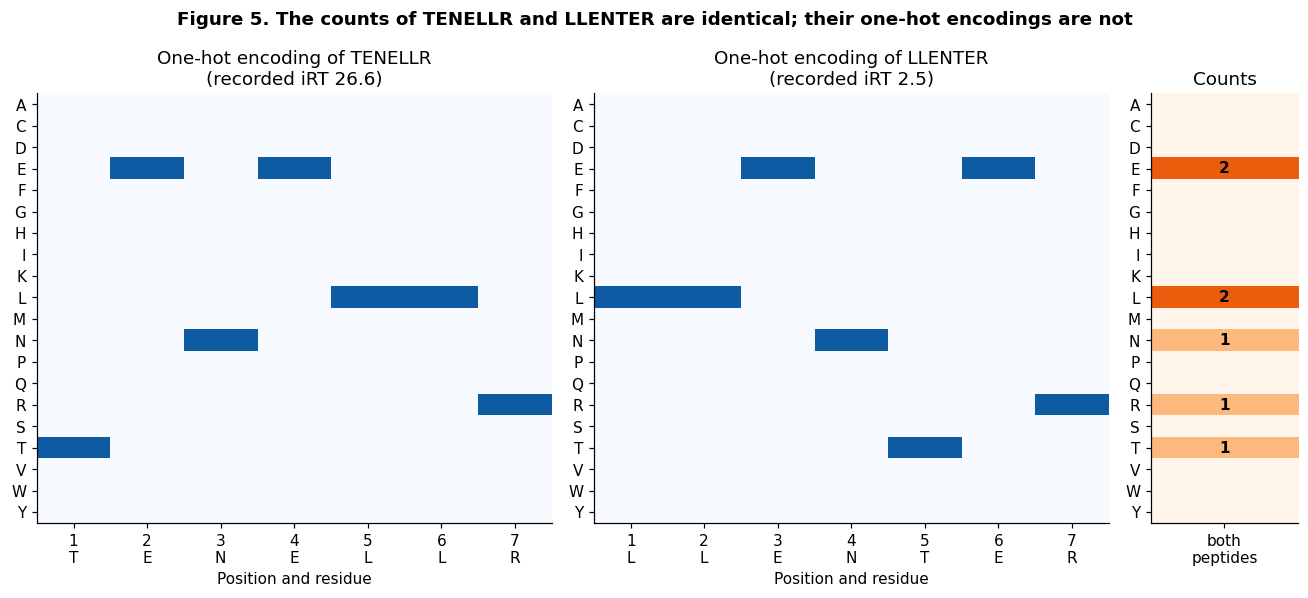

In [11]:
AA_INDEX = {aa: i for i, aa in enumerate(AMINO_ACIDS)}  # A -> 0, C -> 1, ..., Y -> 19 (enumerate numbers the letters)
MAX_LENGTH = 50  # longer peptides would be truncated; the longest here has 40 residues


def one_hot(sequences):
    """Encode peptides as (number of peptides, MAX_LENGTH, 20) arrays, plus their lengths."""
    sequences = list(sequences)
    x = np.zeros((len(sequences), MAX_LENGTH, len(AMINO_ACIDS)), dtype=np.float32)  # a 3D block of zeros: peptides x positions x amino acids
    for n, sequence in enumerate(sequences):  # n = peptide number
        for position, aa in enumerate(sequence[:MAX_LENGTH]):  # each residue of this peptide
            x[n, position, AA_INDEX[aa]] = 1.0  # put a 1 in the column of this amino acid
    lengths = torch.tensor([min(len(s), MAX_LENGTH) for s in sequences])  # the real length of each peptide
    return torch.tensor(x), lengths  # PyTorch tensors: arrays that PyTorch can learn from


pair = ["TENELLR", "LLENTER"]  # same composition, different order (section 5)
fig, axes = plt.subplots(1, 3, figsize=(12, 5.5), gridspec_kw={"width_ratios": [7, 7, 2]})
for ax, peptide in zip(axes[:2], pair):  # the first two plot areas, one per peptide
    x_peptide, _ = one_hot([peptide])
    # imshow draws a table of numbers as coloured cells; .T swaps rows and columns
    ax.imshow(x_peptide[0, :len(peptide)].numpy().T, cmap="Blues", aspect="auto", vmin=0, vmax=1.2)
    ax.set_xticks(range(len(peptide)), [f"{i + 1}\n{aa}" for i, aa in enumerate(peptide)])
    ax.set_yticks(range(20), list(AMINO_ACIDS))
    ax.set_xlabel("Position and residue")
    ax.grid(False)
    recorded = train.set_index("sequence").loc[peptide, "irt"]
    ax.set_title(f"One-hot encoding of {peptide}\n(recorded iRT {recorded:.1f})")
# Count vector of TENELLR (identical for LLENTER), drawn as one column
counts = count_features(pd.Series([pair[0]]))[list(AMINO_ACIDS)].to_numpy().T
axes[2].imshow(counts, cmap="Oranges", aspect="auto", vmin=0, vmax=3)
for row, value in enumerate(counts[:, 0]):
    if value:  # write the count only where it is not zero
        axes[2].text(0, row, int(value), ha="center", va="center", fontweight="bold")
axes[2].set_xticks([0], ["both\npeptides"])
axes[2].set_yticks(range(20), list(AMINO_ACIDS))
axes[2].grid(False)
axes[2].set_title("Counts")
fig.suptitle("Figure 5. The counts of TENELLR and LLENTER are identical; their one-hot encodings are not",
             fontweight="bold")
fig.tight_layout()
plt.show()

### The model: a bidirectional GRU

A **GRU** (gated recurrent unit) is a recurrent neural network, as introduced in lecture 5.1.
It reads the peptide one residue at a time and updates an internal memory after each residue.
The memory can store information such as "the peptide started with two leucines" or "a lysine
came just after a hydrophobic stretch".

Our GRU is **bidirectional**: one GRU reads from the N- to the C-terminus, a second one reads from
the C- to the N-terminus. Their two final memories are combined, and a small neural network turns
them into one iRT prediction. Nobody tells the model that the termini or the length matter.
It must learn this from the training peptides.

**Training details.** The model learns from the training peptides in small batches. After each
pass over the training data (one *epoch*), we measure the validation MAE. When this error stops
improving, the size of the learning steps is halved, so the model can settle more precisely.
We keep the model from the best epoch and stop when the validation error has not improved for
15 epochs. This is called **early stopping**. It prevents the model from memorising the training
peptides.

**What one learning step does** (the inner loop of `train_gru` in the next cell):

1. take a **batch** of 64 training peptides;
2. **predict** their iRT with the current model (`model(...)`);
3. compute the **loss**: how far the predictions are from the recorded values;
4. **backpropagation** (`loss.backward()`): PyTorch computes, for every learnable number, in which
   direction it should change to reduce the loss;
5. the **optimizer** (`optimizer.step()`) changes all learnable numbers a little in that direction.

One **epoch** repeats this until every training peptide has been used once.

In [12]:
# A PyTorch model is a class based on nn.Module. __init__ creates the parts (layers) and their
# learnable numbers; forward describes how the input flows through these parts.
class PeptideGRU(nn.Module):
    """Bidirectional GRU that reads a one-hot peptide and predicts one number."""

    def __init__(self, hidden_size=64):
        super().__init__()  # standard first line of every nn.Module
        # Bidirectional GRU: one GRU reads N -> C, a second one reads C -> N.
        # batch_first=True: the input is arranged as [peptides, positions, amino acids].
        self.gru = nn.GRU(input_size=len(AMINO_ACIDS), hidden_size=hidden_size,
                          batch_first=True, bidirectional=True)
        # Small network that turns the two memories (2 x 64 numbers) into one number.
        # nn.Linear multiplies by learnable weights; nn.ReLU sets negative values to zero.
        self.head = nn.Sequential(nn.Linear(2 * hidden_size, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x, lengths):
        # Packing tells the GRU where each peptide ends, so the zero padding is ignored
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, final_memory = self.gru(packed)          # one memory vector per reading direction
        summary = torch.cat([final_memory[0], final_memory[1]], dim=1)  # put the two memories side by side
        return self.head(summary).squeeze(1)  # one number per peptide


def train_gru(train_sequences, train_targets, validation_sequences, validation_targets,
              max_epochs=150, patience=15, batch_size=64, seed=SEED, verbose=True):
    """Train a PeptideGRU with early stopping. Returns a predict function and the training history."""
    # Fix the random choices (initial weights, order of peptides) so a run can be repeated
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    # Target scaling is learned from training peptides only
    mean, std = float(np.mean(train_targets)), float(np.std(train_targets))  # networks learn better with targets around 0, spread about 1
    # Encode the peptides (tr = training, va = validation)
    x_tr, len_tr = one_hot(train_sequences)
    x_va, len_va = one_hot(validation_sequences)
    target = torch.tensor((np.asarray(train_targets) - mean) / std, dtype=torch.float32)

    # A new, untrained model. The optimizer (AdamW) will change its learnable numbers:
    # lr is the learning rate (step size); weight_decay gently pulls the weights towards zero.
    model = PeptideGRU()
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    # Halve the learning step when the validation error stops improving for 4 epochs
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)
    history, best = [], {"mae": np.inf, "epoch": 0}
    start_time = time.time()
    # Training loop. One epoch = one pass over all training peptides, in small batches.
    # Each learning step: predict a batch, compute the loss (the error), backpropagate
    # (loss.backward() works out how each learnable number should change), then update
    # the numbers (optimizer.step()).
    for epoch in range(1, max_epochs + 1):
        model.train()  # training mode
        order = torch.randperm(len(target), generator=generator)  # shuffle the peptides at each epoch
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]  # indices of the peptides in this batch
            optimizer.zero_grad()  # forget the gradients of the previous step
            loss = nn.functional.smooth_l1_loss(model(x_tr[batch], len_tr[batch]), target[batch])  # smooth L1: like the absolute error, but gentler near zero
            loss.backward()  # backpropagation: compute the gradients
            optimizer.step()  # update the learnable numbers

        model.eval()  # evaluation mode; torch.no_grad(): no learning, so no gradients needed
        with torch.no_grad():
            train_mae = mean_absolute_error(train_targets, model(x_tr, len_tr).numpy() * std + mean)
            val_mae = mean_absolute_error(validation_targets, model(x_va, len_va).numpy() * std + mean)
        scheduler.step(val_mae)  # halve the learning rate if the validation error stopped improving
        history.append({"epoch": epoch, "Training MAE": train_mae, "Validation MAE": val_mae})
        if val_mae < best["mae"]:  # new best validation error: keep a copy of the model
            best = {"mae": val_mae, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        if verbose and epoch % 10 == 0:
            print(f"  epoch {epoch:3d}   training MAE {train_mae:6.2f}   validation MAE {val_mae:6.2f}"
                  f"   ({time.time() - start_time:.0f} s)")
        if epoch - best["epoch"] >= patience:  # early stopping: no improvement for `patience` epochs
            break

    model.load_state_dict(best["state"])  # go back to the best epoch
    model.eval()
    if verbose:
        print(f"Stopped after epoch {epoch}; kept the model from epoch {best['epoch']}.")

    def predict(sequences):
        x, lengths = one_hot(sequences)
        with torch.no_grad():
            return (model(x, lengths).numpy() * std + mean).astype(float)  # undo the target scaling

    return predict, pd.DataFrame(history), best["epoch"], model


# Train the GRU. The function returns four things, which we store under four names.
gru_predict, gru_history, gru_best_epoch, gru_model = train_gru(
    train["sequence"], y_train, validation["sequence"], y_validation)
# Count the learnable numbers (parameters) of the model
print(f"Number of trainable parameters: {sum(p.numel() for p in gru_model.parameters()):,}\n")
record("Sequence model (GRU)", gru_predict(train["sequence"]), gru_predict(validation["sequence"]))

  epoch  10   training MAE   7.37   validation MAE   7.87   (22 s)


  epoch  20   training MAE   5.97   validation MAE   6.55   (44 s)


  epoch  30   training MAE   6.01   validation MAE   7.05   (69 s)


  epoch  40   training MAE   4.10   validation MAE   5.85   (94 s)


  epoch  50   training MAE   3.79   validation MAE   5.99   (118 s)


Stopped after epoch 59; kept the model from epoch 44.
Number of trainable parameters: 41,345



Sequence model (GRU)             training MAE   3.68   validation MAE   5.73   (iRT units)


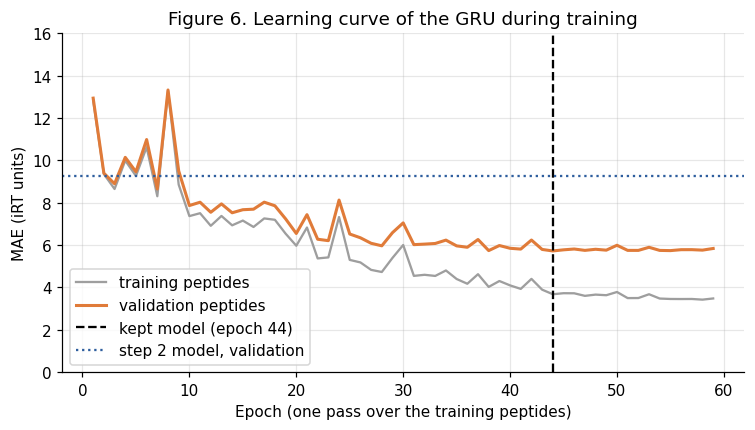

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
# One line per error; gru_history is a table with one row per epoch
ax.plot(gru_history["epoch"], gru_history["Training MAE"], label="training peptides", color="#9E9E9E")
ax.plot(gru_history["epoch"], gru_history["Validation MAE"], label="validation peptides",
        color=MODEL_COLORS["Sequence model (GRU)"], lw=2)
# Vertical line at the kept epoch, horizontal line at the validation error of step 2
ax.axvline(gru_best_epoch, color="black", ls="--", label=f"kept model (epoch {gru_best_epoch})")
ax.axhline(results["Composition + position (Ridge)"]["Validation MAE"], color=MODEL_COLORS[
    "Composition + position (Ridge)"], ls=":", label="step 2 model, validation")
ax.set(xlabel="Epoch (one pass over the training peptides)", ylabel="MAE (iRT units)",
       ylim=(0, 16), title="Figure 6. Learning curve of the GRU during training")
ax.legend()
plt.show()

**What to notice in Figure 6.** In the first epochs both errors fall quickly and the GRU passes the
step 2 model (dotted line). Later, the training error keeps falling while the validation error
levels off. The growing gap means the model starts to learn details that are specific to the
training peptides. Early stopping keeps the
model from the epoch with the lowest validation error. The curves are jumpy at the start, when
the learning steps are large, and become smoother once the step size has been halved.

Because the validation peptides were used to choose the epoch, the validation MAE of the GRU is
slightly optimistic. The test peptides in section 9 give the independent estimate.

## 8. Compare the approaches on validation peptides

,Training MAE,Validation MAE,Reduction vs step 1
Training mean,37.82,37.36,
Composition (Ridge),12.39,12.66,0%
Composition + position (Ridge),8.92,9.27,27%
Sequence model (GRU),3.68,5.73,55%


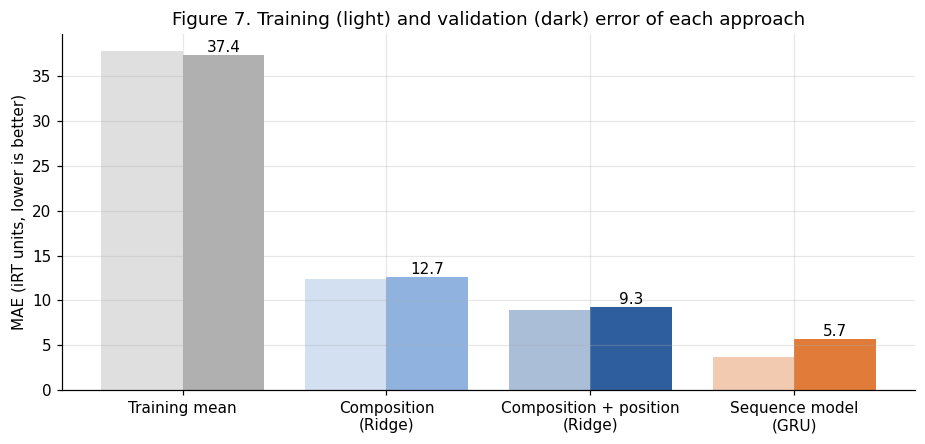

Chosen on validation MAE: Sequence model (GRU)


In [14]:
comparison = pd.DataFrame(results).T  # dictionary -> table; .T puts one approach per row
# Relative reduction of the validation error compared with the composition model
comparison["Reduction vs step 1"] = (
    1 - comparison["Validation MAE"] / comparison.loc["Composition (Ridge)", "Validation MAE"])
comparison.loc["Training mean", "Reduction vs step 1"] = np.nan  # not meaningful for the baseline
# .style.format controls how the numbers are shown (2 decimals, percentages)
display(comparison.style.format({"Training MAE": "{:.2f}", "Validation MAE": "{:.2f}",
                                  "Reduction vs step 1": "{:.0%}"}, na_rep=""))

fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(comparison))  # x positions 0, 1, 2, 3 of the pairs of bars
# Two bars per approach: training (light, shifted left) and validation (dark, shifted right)
ax.bar(positions - 0.2, comparison["Training MAE"], width=0.4, label="training",
       color=[MODEL_COLORS[n] for n in comparison.index], alpha=0.4)
bars = ax.bar(positions + 0.2, comparison["Validation MAE"], width=0.4, label="validation",
              color=[MODEL_COLORS[n] for n in comparison.index])
ax.bar_label(bars, fmt="%.1f")
ax.set_xticks(positions, [n.replace(" (", "\n(") for n in comparison.index])
ax.set(ylabel="MAE (iRT units, lower is better)",
       title="Figure 7. Training (light) and validation (dark) error of each approach")
plt.show()

chosen_name = comparison["Validation MAE"].idxmin()  # the approach with the lowest validation MAE
print(f"Chosen on validation MAE: {chosen_name}")

**What to notice in Figure 7.** Each step lowers the validation error. Step 2 shows that better
features can improve a simple model a lot. Step 3 gives the largest gain: the GRU roughly halves
the error of the reference composition model or better. A more complex model is not always better: the
random forest in the instructor copy did worse than the linear model. The GRU helps here because
it can use information that the count features do not contain at all, namely the order of the
residues. We check this directly below.

### Does the GRU really use the order of the residues?

We take each validation peptide and shuffle its residues, keeping the C-terminal K or R in place.
The composition stays the same; only the order changes. We then measure how much each model's
prediction changes. We do not know the true iRT of the shuffled peptides, so this test says
nothing about accuracy. It only shows which information each model uses.

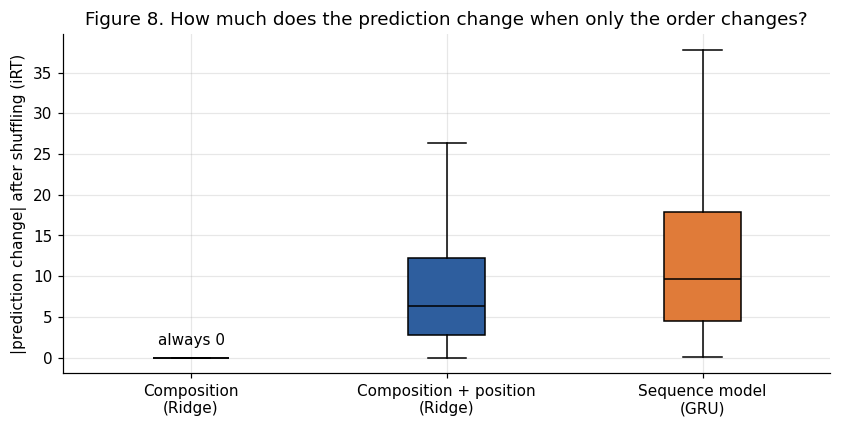

Composition (Ridge)              median change   0.0 iRT units
Composition + position (Ridge)   median change   6.4 iRT units
Sequence model (GRU)             median change   9.7 iRT units


In [15]:
rng = np.random.default_rng(SEED)  # a random number generator with a fixed seed


def shuffle_keep_c_terminus(sequence):
    middle = list(sequence[:-1])  # all residues except the last one, as a list of letters
    rng.shuffle(middle)  # put them in a random order
    return "".join(middle) + sequence[-1]  # glue them back together and add the C-terminal K or R


shuffled = validation["sequence"].map(shuffle_keep_c_terminus)
# A dictionary of prediction functions, one per model ('lambda s: ...' is a one-line function)
predictors = {
    "Composition (Ridge)": lambda s: composition_model.predict(count_features(s)),
    "Composition + position (Ridge)": lambda s: position_model.predict(position_features(s)),
    "Sequence model (GRU)": gru_predict,
}
# For each model: size of the prediction change when only the order of the residues changes
order_effect = {name: np.abs(f(shuffled) - f(validation["sequence"])) for name, f in predictors.items()}

fig, ax = plt.subplots(figsize=(9, 4))
box = ax.boxplot(list(order_effect.values()), showfliers=False, patch_artist=True,
                 medianprops={"color": "black"})
for patch, name in zip(box["boxes"], order_effect):  # colour each box like its model
    patch.set_facecolor(MODEL_COLORS[name])
ax.annotate("always 0", (1, 0), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_xticks(range(1, 4), [n.replace(" (", "\n(") for n in order_effect])
ax.set(ylabel="|prediction change| after shuffling (iRT)",
       title="Figure 8. How much does the prediction change when only the order changes?")
plt.show()
for name, change in order_effect.items():
    print(f"{name:32s} median change {np.median(change):5.1f} iRT units")

**What to notice in Figure 8.** The composition model gives exactly the same prediction after
shuffling: it cannot see order. The step 2 model reacts clearly, but only through the three
N-terminal positions. The GRU reacts the most, because it reads the full sequence. Section 5 showed that
recorded iRT values of peptides with the same composition can differ by more than 20 units,
so this sensitivity to order is needed.

### What has the GRU learned? An in-silico mutation scan

We take one validation peptide and replace each residue, one at a time, by each of the
20 amino acids. For every variant we compute the change in predicted iRT. Red means the variant is
predicted to elute later; blue means earlier. The black dots mark the original residues
(change = 0). This is a common way to look inside a neural network: change the input a little
and watch the output.

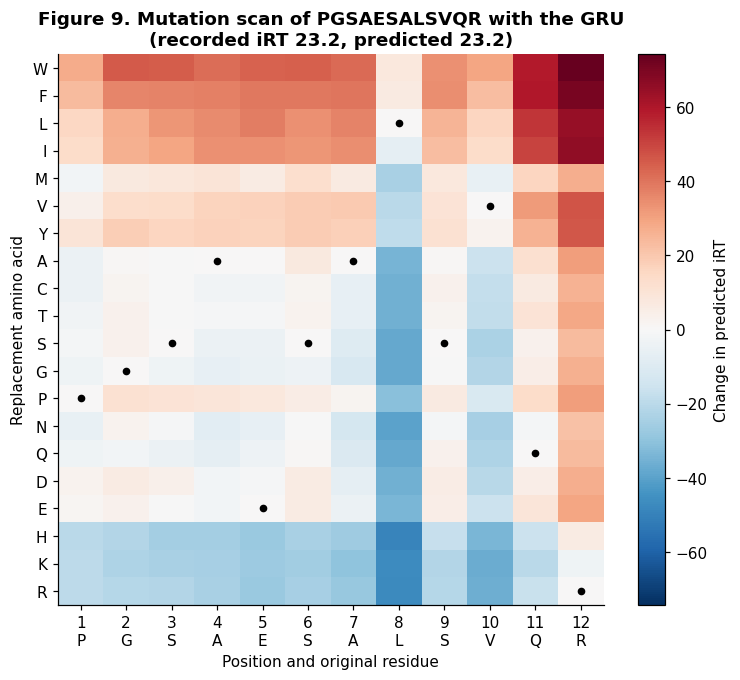

In [16]:
# A validation peptide of typical length that the GRU predicts well
scan_peptide = "PGSAESALSVQR"
assert scan_peptide in set(validation["sequence"])

reference = gru_predict([scan_peptide])[0]  # prediction for the original peptide
# Every single-residue variant: letters before position p + new amino acid + letters after p
variants = [scan_peptide[:p] + aa + scan_peptide[p + 1:]
            for p in range(len(scan_peptide)) for aa in AMINO_ACIDS]
# Predict all variants at once and subtract the original prediction. .reshape arranges the
# results as positions x amino acids; .T swaps them to amino acids (rows) x positions (columns).
change = (gru_predict(variants) - reference).reshape(len(scan_peptide), len(AMINO_ACIDS)).T

row_order = [aa for aa in "WFLIMVYACTSGPNQDEHKR"]  # roughly from hydrophobic to basic
change = pd.DataFrame(change, index=list(AMINO_ACIDS)).loc[row_order]  # reorder the rows
limit = np.abs(change.to_numpy()).max()  # same colour range for red and blue

fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(change, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")  # red = later, blue = earlier
for p, aa in enumerate(scan_peptide):  # a black dot on each original residue
    ax.plot(p, row_order.index(aa), "o", color="black", ms=4)
ax.set_xticks(range(len(scan_peptide)), [f"{p + 1}\n{aa}" for p, aa in enumerate(scan_peptide)])
ax.set_yticks(range(20), row_order)
ax.set(xlabel="Position and original residue", ylabel="Replacement amino acid")
ax.grid(False)
fig.colorbar(image, label="Change in predicted iRT")
ax.set_title(f"Figure 9. Mutation scan of {scan_peptide} with the GRU\n"
             f"(recorded iRT {validation.set_index('sequence').loc[scan_peptide, 'irt']:.1f}, "
             f"predicted {reference:.1f})", fontweight="bold")
plt.show()

**What to notice in Figure 9.**

- Within each column, hydrophobic and aromatic replacements (top rows) increase the predicted iRT,
  and basic replacements K, R, H (bottom rows) decrease it. The GRU has learned the same chemistry
  as the composition model in Figure 2.
- The size of the effect depends on the position. Compare the first column with positions 4 to 7:
  adding a hydrophobic residue at the N-terminus raises the prediction much less.
  This matches the N-terminal effect found in Figure 3b, but here the model learned it without
  being told. A composition model gives each amino acid one fixed contribution wherever it occurs.
- The last column needs care. Every training peptide ends in K or R, so the model has never seen
  a peptide with another C-terminal residue. The large changes in that column are extrapolations
  outside the training data and should not be trusted. Swapping R for K, which does occur in the
  data, changes the prediction very little.

### How much training data does each approach need?

We train each model again on smaller random subsets of the training peptides and measure the
validation MAE. This cell retrains the GRU three times and takes about 2 minutes on a CPU.

  450 training peptides: 12.98   10.38   9.01


  900 training peptides: 12.75   9.87   8.29


 1800 training peptides: 12.70   9.59   7.66


 3600 training peptides: 12.66   9.27   5.73


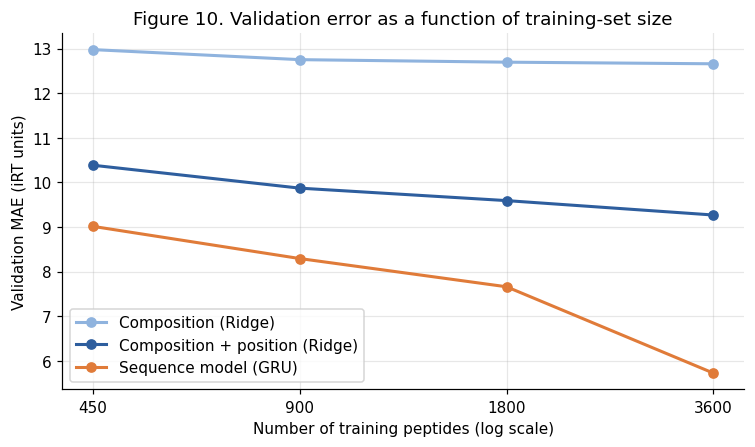

In [17]:
sizes = [450, 900, 1800, len(train)]  # numbers of training peptides to try
curve = {name: [] for name in ["Composition (Ridge)", "Composition + position (Ridge)", "Sequence model (GRU)"]}  # one empty list of results per model
for size in sizes:
    subset = train.sample(n=size, random_state=SEED) if size < len(train) else train  # a random subset of the training peptides
    # Refit both linear models on the subset (a function can be stored in a list, like a value)
    for name, features in [("Composition (Ridge)", count_features),
                           ("Composition + position (Ridge)", position_features)]:
        model = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(features(subset["sequence"]), subset["irt"])
        curve[name].append(mean_absolute_error(y_validation, model.predict(features(validation["sequence"]))))
    if size == len(train):  # the GRU on all training peptides was already trained above
        curve["Sequence model (GRU)"].append(results["Sequence model (GRU)"]["Validation MAE"])
    else:
        predict_subset, *_ = train_gru(subset["sequence"], subset["irt"].to_numpy(),  # *_ ignores the other returned values
                                       validation["sequence"], y_validation, verbose=False)
        curve["Sequence model (GRU)"].append(
            mean_absolute_error(y_validation, predict_subset(validation["sequence"])))
    print(f"{size:5d} training peptides: " + "   ".join(f"{v[-1]:.2f}" for v in curve.values()))

fig, ax = plt.subplots(figsize=(8, 4.2))
for name, values in curve.items():
    ax.plot(sizes, values, "o-", lw=2, color=MODEL_COLORS[name], label=name)
ax.set_xscale("log", base=2)  # each doubling of the data has the same width
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.set(xlabel="Number of training peptides (log scale)", ylabel="Validation MAE (iRT units)",
       title="Figure 10. Validation error as a function of training-set size")
ax.legend()
plt.show()

**What to notice in Figure 10.**

- The composition model hardly improves with more data. Its 21 features limit what it can learn,
  and a few hundred peptides are enough to estimate them.
- The step 2 model improves slowly: it has 102 features, so it benefits a little from more data.
- The GRU improves the most. Its error is still falling at 3,600 peptides, so more data would
  probably help further. With this data set the GRU is already better at 450 peptides, but that
  is not guaranteed for other data: with very few peptides, simple models are often safer.

This is why published retention-time predictors, such as DeepLC, Prosit or AlphaPeptDeep, are
trained on hundreds of thousands of peptides.

## 9. Final check on the test peptides

The choice of model is now fixed, based on validation MAE only. We evaluate all approaches on the
test peptides once, for context, and do not change anything afterwards. Besides the MAE we report:

- **Median error**: half of the peptides have a smaller error than this value.
- **95th percentile error**: 95% of the peptides have a smaller error than this value. It shows
  whether the average hides large mistakes.
- **R²**: the fraction of the variation in iRT that the model explains (1 is perfect, 0 is no
  better than the mean).

In [18]:
# Predictions of every approach for the test peptides, stored by name
test_predictions = {
    "Training mean": baseline.predict(X_test_counts),
    "Composition (Ridge)": composition_model.predict(X_test_counts),
    "Composition + position (Ridge)": position_model.predict(X_test_position),
    "Sequence model (GRU)": gru_predict(test["sequence"]),
}
# A dictionary comprehension computes four measures per approach; .T puts one approach per row.
# np.percentile(..., 95): 95% of the peptides have a smaller error than this value.
test_table = pd.DataFrame({
    name: {"Test MAE": mean_absolute_error(y_test, p),
           "Median error": np.median(np.abs(y_test - p)),
           "95th percentile error": np.percentile(np.abs(y_test - p), 95),
           "R²": r2_score(y_test, p)}
    for name, p in test_predictions.items()}).T
print(f"Model chosen on validation: {chosen_name}")
display(test_table.style.format("{:.2f}"))

Model chosen on validation: Sequence model (GRU)


,Test MAE,Median error,95th percentile error,R²
Training mean,39.54,36.50,85.03,-0.00
Composition (Ridge),12.41,10.15,31.37,0.88
Composition + position (Ridge),8.86,6.78,24.21,0.94
Sequence model (GRU),5.82,4.34,16.20,0.97


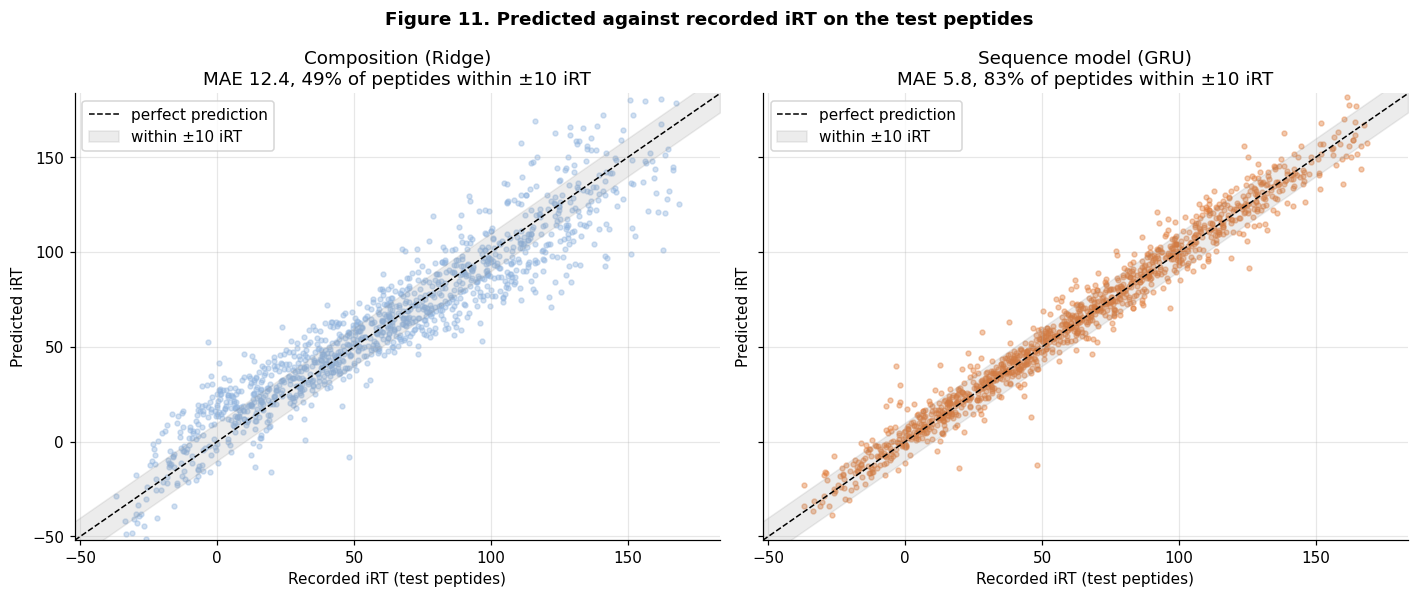

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)  # both plots use the same axis ranges
limits = [y_test.min() - 15, y_test.max() + 15]  # axis range with some margin
for ax, name in zip(axes, ["Composition (Ridge)", chosen_name]):  # left: step 1, right: the chosen model
    prediction = test_predictions[name]
    ax.scatter(y_test, prediction, s=10, alpha=0.4, color=MODEL_COLORS[name])
    ax.plot(limits, limits, color="black", ls="--", lw=1, label="perfect prediction")
    # Grey band: within ±10 iRT units of the diagonal
    ax.fill_between(limits, [l - 10 for l in limits], [l + 10 for l in limits], color="grey",
                    alpha=0.15, label="within ±10 iRT")
    within = np.mean(np.abs(y_test - prediction) <= 10)  # fraction of peptides within ±10 (True counts as 1)
    ax.set(xlim=limits, ylim=limits, xlabel="Recorded iRT (test peptides)", ylabel="Predicted iRT",
           title=f"{name}\nMAE {mean_absolute_error(y_test, prediction):.1f}, "
                 f"{within:.0%} of peptides within ±10 iRT")
    ax.legend(loc="upper left")
fig.suptitle("Figure 11. Predicted against recorded iRT on the test peptides", fontweight="bold")
fig.tight_layout()
plt.show()

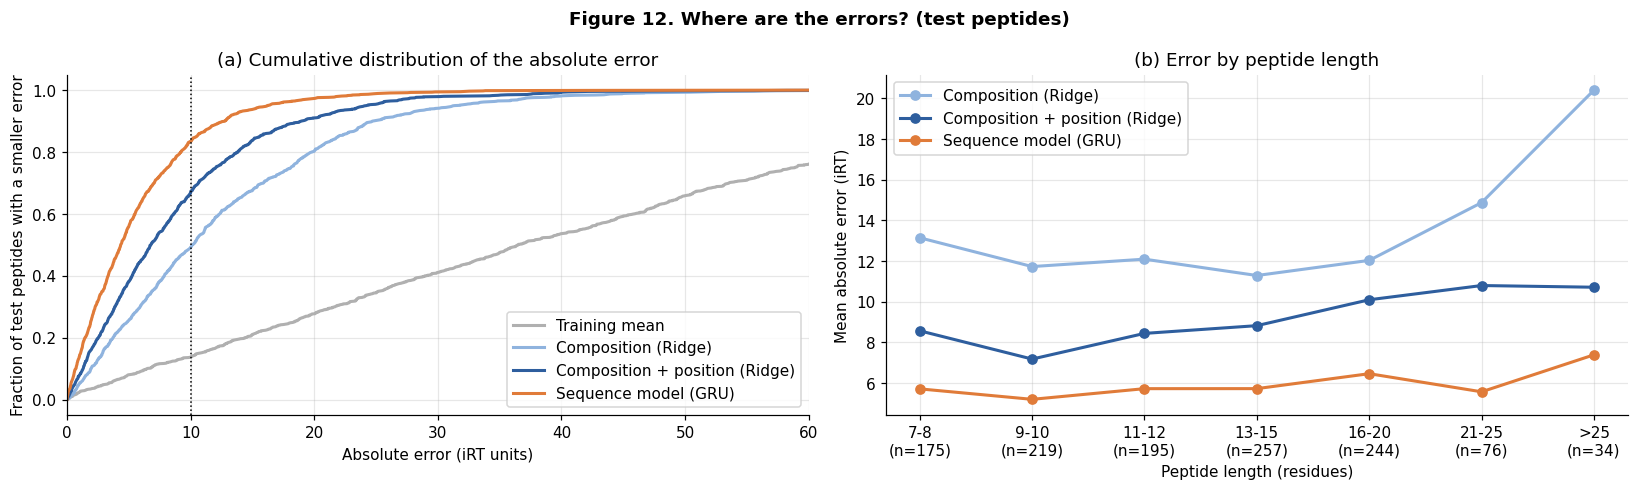

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, prediction in test_predictions.items():
    # Sort the errors; the fraction of peptides below each error rises from 0 to 1
    error = np.sort(np.abs(y_test - prediction))
    axes[0].plot(error, np.arange(1, len(error) + 1) / len(error), lw=2,
                 color=MODEL_COLORS[name], label=name)
axes[0].axvline(10, color="black", ls=":", lw=1)
axes[0].set(xlim=(0, 60), xlabel="Absolute error (iRT units)",
            ylabel="Fraction of test peptides with a smaller error",
            title="(a) Cumulative distribution of the absolute error")
axes[0].legend(loc="lower right")

# (b) Same length groups as in Figure 3; mean error per group for each model
test_length_group = pd.cut(test["sequence"].str.len(), [0, 8, 10, 12, 15, 20, 25, 100],
                           labels=length_labels)
for name in ["Composition (Ridge)", "Composition + position (Ridge)", "Sequence model (GRU)"]:
    error = pd.Series(np.abs(y_test - test_predictions[name]), index=test.index)
    axes[1].plot(length_labels, error.groupby(test_length_group, observed=False).mean(), "o-", lw=2,
                 color=MODEL_COLORS[name], label=name)
group_sizes = test_length_group.value_counts().reindex(length_labels)  # number of peptides per group, in label order
axes[1].set_xticks(range(len(length_labels)),
                   [f"{label}\n(n={n})" for label, n in zip(length_labels, group_sizes)])
axes[1].set(xlabel="Peptide length (residues)", ylabel="Mean absolute error (iRT)",
            title="(b) Error by peptide length")
axes[1].legend()
fig.suptitle("Figure 12. Where are the errors? (test peptides)", fontweight="bold")
fig.tight_layout()
plt.show()

**How to read Figure 12a.** Each curve shows, for a given error threshold on the x-axis, which
fraction of the test peptides is predicted at least that well. A curve that rises faster and
further to the left is better. The dotted line marks an error of 10 iRT units.

In [21]:
# A table of the test peptides with the predictions of the three models and a few properties
review = test[["sequence", "irt"]].copy()
review["step 1 prediction"] = test_predictions["Composition (Ridge)"]
review["step 2 prediction"] = test_predictions["Composition + position (Ridge)"]
review["final prediction"] = test_predictions[chosen_name]
review["absolute error"] = np.abs(review["irt"] - review["final prediction"])
review["length"] = review["sequence"].str.len()
review["H"] = review["sequence"].str.count("H")
review["K + R"] = review["sequence"].str.count("K") + review["sequence"].str.count("R")
review.nlargest(8, "absolute error").round(1)  # the 8 rows with the largest error

,sequence,irt,step 1 prediction,step 2 prediction,final prediction,absolute error,length,H,K + R
1073,VGDTEGEYHR,48.1,-8.3,-27.4,-12.5,60.6,10,1,1
2338,LIEVDDER,-3.2,52.3,36.7,39.8,43.0,8,0,1
5808,HHSETNFGVK,19.8,-16.1,-20.2,-14.1,33.8,10,2,1
3289,AAAEGLMSLLR,125.5,78.8,83.3,91.8,33.7,11,0,1
1765,SELVVDKTK,45.8,19.0,17.5,13.2,32.5,9,0,2
240,TGDAISVMSEVAQTLLTQDVR,123.9,114.5,122.9,156.1,32.2,21,0,1
149,EDGNSISSMMVK,-2.0,30.4,36.6,29.8,31.8,12,0,1
5060,DLMEAISK,28.2,45.1,47.1,58.0,29.8,8,0,1


**What to notice in the test results**

- Figure 11: the composition model scatters widely and its errors grow at high iRT. The GRU
  points lie in a narrow band around the diagonal.
- Figure 12a: the GRU curve rises fastest. A larger fraction of the peptides is predicted within
  any given error.
- Figure 12b: the error of the composition model grows sharply for peptides longer than 20
  residues. The GRU error stays almost constant with length.

**The largest errors.** For several of the worst peptides, all three models agree with each other
but disagree with the recorded iRT. For example, every model predicts that VGDTEGEYHR elutes
early, but its recorded iRT is about 48. When very different models agree, the recorded value may
be questionable, for example because of a wrong peak or a misidentified spectrum. It may also be
a real effect that none of the models captures. We cannot decide this from these data alone.
We should not remove such peptides from the test set only because they are hard to predict.
A low average error does not guarantee that every peptide is predicted well.

## 10. Summary: what made the predictions better, and why

In [22]:
# For each approach: (what the model sees, why it helps). Round brackets make a pair (a tuple).
explanations = {
    "Training mean": ("nothing", "reference point"),
    "Composition (Ridge)": ("amino-acid counts and length",
                            "learns one retention contribution per residue (Figure 2)"),
    "Composition + position (Ridge)": ("+ fractions, log length, first three residues",
                                       "corrects length and N-terminal effects (Figures 3 and 4)"),
    "Sequence model (GRU)": ("full sequence in order",
                             "learns order, neighbour and position effects (Figures 8 and 9)"),
}
# Build the summary table column by column; e[0] and e[1] are the two parts of each pair
summary = pd.DataFrame({
    "Model sees": {n: e[0] for n, e in explanations.items()},
    "Why it helps": {n: e[1] for n, e in explanations.items()},
    "Validation MAE": comparison["Validation MAE"],
    "Test MAE": test_table["Test MAE"],
})
display(summary.style.format({"Validation MAE": "{:.2f}", "Test MAE": "{:.2f}"}))

,Model sees,Why it helps,Validation MAE,Test MAE
Training mean,nothing,reference point,37.36,39.54
Composition (Ridge),amino-acid counts and length,learns one retention contribution per residue (Figure 2),12.66,12.41
Composition + position (Ridge),"+ fractions, log length, first three residues",corrects length and N-terminal effects (Figures 3 and 4),9.27,8.86
Sequence model (GRU),full sequence in order,"learns order, neighbour and position effects (Figures 8 and 9)",5.73,5.82


**Main lessons**

1. **Look at the errors before changing the model.** The residual plots (Figure 3) showed which
   information was missing. Each new feature answered one specific finding.
2. **Better features can matter as much as a better algorithm.** Step 2 kept the same linear
   model and still reduced the error clearly.
3. **A more complex model helps only if it can use information the simpler model cannot.**
   The random forest of the instructor copy used the same counts and did not help. The GRU reads
   the order of the residues, which counts do not contain, and more than halves the error.
4. **Neural networks need data.** Figure 10 shows that the GRU keeps improving with more training
   peptides, while the linear models stop improving early.
5. **Check, do not trust.** The hand checks, the feature ablation, the shuffle test and the final
   test set are all ways to verify claims, including claims made by an LLM.

**Limits of this result**

- iRT is a calibrated index, not a time. To predict minutes on another LC system, the predictions
  must be calibrated with peptides measured on that system.
- The data contain no modified peptides, one peptide population (synthetic tryptic peptides) and
  one LC method. Performance on modified peptides, other proteases or other LC methods is untested.
- A sequence-disjoint split can still contain closely related peptides, so the test error may be
  slightly optimistic for very different peptides.
- Published tools trained on much larger data reach lower errors. DeepLC, for example, also handles
  modified peptides by describing residues through their atomic composition.

## Questions for discussion

1. In Figure 2, why do K, R and H lower retention while D and E barely change it? What would you
   expect at neutral pH?
2. The GRU has many more parameters than there are training peptides. Why does it not simply
   memorise them? Use Figure 6 in your answer.
3. Figure 10 suggests the GRU would improve with more data. How would you test this claim with the
   full DLOmix file without touching the current test peptides?
4. Choose one of the largest errors in section 9. Propose a chemical reason for the error and a
   change to the features or data that could reduce it.

## Data and reuse

The [DLOmix example CSV](https://raw.githubusercontent.com/wilhelm-lab/dlomix/f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv) contains 34,000 peptide sequences with experimentally
derived iRT targets. We use a fixed random subset of 6,000. The
[ProteomicsML description](https://proteomicsml.org/datasets/retentiontime/DLOmix_RT.html)
connects these data to [ProteomeTools](https://doi.org/10.1038/nmeth.4153), PXD004732.
Credit the experimental authors and the DLOmix contributors. The source is distributed
in the [MIT-licensed DLOmix repository](https://github.com/wilhelm-lab/dlomix/blob/f67623048c8692823cff88c3a7521123697af781/LICENSE).

The two-column file lacks modification annotations, run and batch identifiers, and detailed
LC conditions. Plain sequence strings do not specify every chemical modification.
A sequence-disjoint split can still contain related peptides and does not validate transfer
to another laboratory. Converting iRT to experimental time requires local calibration.
See the [dataset provenance and backup](https://github.com/CompOmics/ML_AI_Analytical_Chemistry_Course/tree/main/datasets/peptide_rt).
This practical is not a reproduction of a published benchmark.